# Chapter 6: Statistical Machine Learning
**Practical Statistics for Data Scientists (2nd Edition)** — Peter Bruce, Andrew Bruce & Peter Gedeck (O'Reilly)

Notebook ini berisi **reproduksi kode** dan **penjelasan teori** dari Chapter 6, menggunakan dataset pinjaman LendingClub yang sama dengan Chapter 5.

## Ringkasan Chapter
Chapter ini membahas metode *supervised learning* yang termasuk **statistical machine learning**: metode yang dilatih pada data dengan outcome yang diketahui, lalu dipakai untuk memprediksi outcome pada data baru. Bedanya dengan metode statistik klasik, metode ini **digerakkan oleh data** (*data-driven*) dan tidak memaksakan struktur linear atau struktur global lain pada data.

Inti ide chapter ini adalah **ensemble learning**: memakai banyak model untuk membentuk satu prediksi, bukan hanya satu model. Kombinasi ensemble dengan **pohon keputusan** menghasilkan beberapa teknik prediktif *off-the-shelf* terbaik.

| Bagian | Inti |
|---|---|
| K-Nearest Neighbors (KNN) | Klasifikasikan record sesuai kelas record-record yang paling mirip |
| Tree Models | Aturan if-then hasil partisi data berulang (*recursive partitioning*) |
| Bagging dan Random Forest | Rata-rata banyak pohon yang dilatih pada sampel bootstrap |
| Boosting (XGBoost) | Barisan model di mana tiap model memperbaiki kesalahan model sebelumnya |

> **Machine learning vs statistik.** Tidak ada garis tegas di antara keduanya. Machine learning cenderung fokus pada algoritma efisien yang *scalable* untuk data besar, sedangkan statistik lebih memperhatikan teori probabilistik dan struktur model. Bagging dan random forest berkembang di kubu statistik. Boosting berkembang di kedua kubu, tetapi lebih banyak mendapat perhatian di sisi machine learning. Pengembangan banyak teknik ini ditelusuri ke Leo Breiman (UC Berkeley) dan Jerome Friedman (Stanford): model pohon (1984), lalu bagging dan boosting (1990-an).

## 0. Setup dan Persiapan Data

| File | Isi |
|---|---|
| `loan200.csv` | 200 pinjaman dengan dua prediktor (`payment_inc_ratio`, `dti`). Baris pertama (outcome bernilai `target`) adalah pinjaman baru yang akan diprediksi |
| `loan3000.csv` | Sampel 3.000 pinjaman dengan `borrower_score` dan `payment_inc_ratio` |
| `loan_data.csv.gz` | 45.342 pinjaman, seimbang (50% default / 50% paid off) |

> **Catatan versi library.** Buku ditulis untuk versi library yang lebih lama. Pada versi terbaru, ada tiga penyesuaian kecil yang tidak mengubah konsep: (1) XGBoost mewajibkan label numerik (0/1), (2) default `learning_rate` dan `max_depth` XGBoost kini mengikuti booster asli (0,3 dan 6), sehingga nilai yang dipakai buku (0,1 dan 3) kita tulis eksplisit, (3) argumen `ntree_limit` diganti `iteration_range`.

In [1]:
from pathlib import Path
from collections import defaultdict
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pylab as plt
import seaborn as sns

from sklearn import preprocessing, metrics
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.inspection import DecisionBoundaryDisplay
from xgboost import XGBClassifier

from dmba import plotDecisionTree, textDecisionTree

%matplotlib inline
pd.set_option('display.width', 120)

DATA = Path('data')
LOAN200_CSV = DATA / 'loan200.csv'
LOAN3000_CSV = DATA / 'loan3000.csv'
LOAN_DATA_CSV = DATA / 'loan_data.csv.gz'

no display found. Using non-interactive Agg backend


In [2]:
loan200 = pd.read_csv(LOAN200_CSV)
loan200 = loan200.drop(columns=['Unnamed: 0'], errors='ignore')
loan200['outcome'] = loan200['outcome'].astype('category')

loan3000 = pd.read_csv(LOAN3000_CSV)
loan3000 = loan3000.drop(columns=['Unnamed: 0'], errors='ignore')
loan3000['outcome'] = loan3000['outcome'].astype('category')

loan_data = pd.read_csv(LOAN_DATA_CSV)
loan_data = loan_data.drop(columns=['Unnamed: 0', 'status'], errors='ignore')
for col in ['outcome', 'purpose_', 'home_', 'emp_len_']:
    loan_data[col] = loan_data[col].astype('category')

print('loan200  :', loan200.shape)
print('loan3000 :', loan3000.shape)
print('loan_data:', loan_data.shape)
loan200.head()

loan200  : (201, 3)
loan3000 : (3000, 5)
loan_data: (45342, 19)


,outcome,payment_inc_ratio,dti
0,target,9.00000,22.50
1,default,5.46933,21.33
2,paid off,6.90294,8.97
3,paid off,11.14800,1.83
4,default,3.72120,10.81


---
## 1. K-Nearest Neighbors (KNN)

### Teori

Ide KNN sangat sederhana. Untuk tiap record yang akan diklasifikasikan atau diprediksi:
1. Cari **K** record dengan fitur yang mirip (nilai prediktor mirip).
2. Untuk **klasifikasi**: cari kelas mayoritas di antara record-record mirip itu, lalu berikan kelas tersebut pada record baru.
3. Untuk **prediksi numerik** (KNN regression): hitung rata-rata nilai record-record mirip itu, lalu jadikan prediksi.

**Istilah kunci**
- **Neighbor:** record dengan nilai prediktor mirip dengan record lain.
- **Distance metric:** ukuran yang meringkas jarak dua record dalam satu angka.
- **Standardization (normalization):** kurangi rata-rata dan bagi dengan standar deviasi.
- **z-score:** nilai hasil standardisasi.
- **K:** jumlah tetangga yang dipertimbangkan.

KNN **tidak memiliki model yang di-fit** (tidak seperti regresi). Namun bukan berarti prosesnya otomatis: hasil prediksi bergantung pada cara fitur diskalakan, cara kemiripan diukur, dan besar K. Selain itu semua prediktor harus berbentuk numerik.

**Probabilitas dari KNN.** Selain keputusan biner, KNN dapat menghasilkan probabilitas (propensity), yaitu proporsi kelas tertentu di antara K tetangga. Contoh: 9 default dari 20 tetangga berarti probabilitas default 9/20 = 0,45. Probabilitas ini memungkinkan aturan selain voting mayoritas (cutoff 0,5), yang penting untuk kelas tidak seimbang.

### Kode: contoh kecil, prediksi default pinjaman
Dengan 200 pinjaman (`loan200`) dan K = 20, kita prediksi pinjaman baru dengan `dti = 22,5` dan `payment_inc_ratio = 9`. Pinjaman baru tersebut adalah baris pertama (indeks 0) dan dikeluarkan dari data latih.

In [3]:
predictors = ['payment_inc_ratio', 'dti']
outcome = 'outcome'

newloan = loan200.loc[0:0, predictors]
X = loan200.loc[1:, predictors]
y = loan200.loc[1:, outcome]

knn = KNeighborsClassifier(n_neighbors=20)
knn.fit(X, y)
print('prediksi K=20:', knn.predict(newloan)[0])
print('probabilitas :', dict(zip(knn.classes_, knn.predict_proba(newloan)[0])))

# Bandingkan dengan K = 3 (seperti dibahas di buku)
knn3 = KNeighborsClassifier(n_neighbors=3).fit(X, y)
print('prediksi K=3 :', knn3.predict(newloan)[0])

prediksi K=20: paid off
probabilitas : {'default': np.float64(0.45), 'paid off': np.float64(0.55)}
prediksi K=3 : default


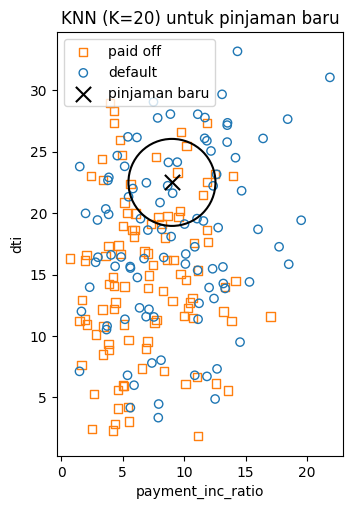

kelas di antara 20 tetangga:
outcome
paid off    11
default      9
target       0
Name: count, dtype: int64


In [4]:
# Visualisasi (Figure 6-2): lingkaran hitam = batas 20 tetangga terdekat
dist, idx = knn.kneighbors(newloan)
radius = dist[0].max()

fig, ax = plt.subplots(figsize=(5.5, 5.5))
for cls, marker, color in [('paid off', 's', 'C1'), ('default', 'o', 'C0')]:
    sub = X[y == cls]
    ax.scatter(sub['payment_inc_ratio'], sub['dti'], marker=marker,
               facecolors='none', edgecolors=color, label=cls)
ax.scatter(newloan['payment_inc_ratio'], newloan['dti'], marker='x', s=120, color='k', label='pinjaman baru')
ax.add_patch(plt.Circle((newloan['payment_inc_ratio'].iloc[0], newloan['dti'].iloc[0]),
                        radius, fill=False, color='k', lw=1.5))
ax.set_aspect('equal')
ax.set_xlabel('payment_inc_ratio'); ax.set_ylabel('dti')
ax.set_title('KNN (K=20) untuk pinjaman baru')
ax.legend()
plt.show()

nbr_classes = y.iloc[idx[0]].value_counts()
print('kelas di antara 20 tetangga:'); print(nbr_classes)

**Interpretasi hasil:**
- Di antara 20 tetangga terdekat terdapat 11 pinjaman *paid off* dan 9 *default*, sehingga prediksi K=20 adalah **paid off** dengan probabilitas default 9/20 = **0,45**. Ini sama dengan Figure 6-2 pada buku.
- Jika hanya 3 tetangga terdekat yang dipakai, prediksinya berubah menjadi **default**. Hasil KNN sangat bergantung pada pilihan K.

### Teori: Distance metrics

Kemiripan diukur dengan **distance metric**. Dua yang paling umum untuk dua vektor $(x_1,\dots,x_p)$ dan $(u_1,\dots,u_p)$:

$$\text{Euclidean} = \sqrt{(x_1-u_1)^2+(x_2-u_2)^2+\cdots+(x_p-u_p)^2}$$

$$\text{Manhattan} = |x_1-u_1|+|x_2-u_2|+\cdots+|x_p-u_p|$$

Jarak Euclidean adalah jarak garis lurus ("jarak burung terbang"). Jarak Manhattan adalah jarak jika bergerak satu arah pada satu waktu (seperti menyusuri blok kota), sehingga berguna sebagai pendekatan jika kemiripan didefinisikan sebagai waktu tempuh titik ke titik.

> **Metrik lain.** **Jarak Mahalanobis** memperhitungkan korelasi antarvariabel dengan memakai matriks kovarians. Dua variabel yang sangat berkorelasi pada dasarnya diperlakukan sebagai satu variabel. Jarak Mahalanobis setara dengan jarak Euclidean pada komponen utama (PCA), tetapi lebih berat secara komputasi.

Variabel berskala besar akan **mendominasi** jarak. Pada data pinjaman, jarak hampir hanya ditentukan oleh `income` dan `loan amount` (puluhan hingga ratusan ribu), sedangkan variabel rasio hampir tidak berpengaruh. Solusinya: standardisasi.

In [5]:
# Ilustrasi jarak antara dua pinjaman
a = np.array([9.0, 22.5]); b = np.array([5.5, 21.3])
print('Euclidean:', round(np.sqrt(((a - b) ** 2).sum()), 4))
print('Manhattan:', round(np.abs(a - b).sum(), 4))

Euclidean: 3.7
Manhattan: 4.7


### Teori: One-hot encoder

Banyak model statistik dan machine learning mengharuskan variabel faktor (string) diubah menjadi variabel dummy biner. Misalnya variabel status rumah dengan empat kategori menjadi empat variabel biner, dan tiap record hanya memiliki satu nilai 1 (sisanya 0). Istilah *one hot* berasal dari rangkaian digital di mana hanya satu bit yang diizinkan bernilai positif ("panas"). Pada regresi linear dan logistik, one hot encoding menimbulkan masalah multikolinearitas sehingga satu dummy dibuang. Pada KNN dan metode lain di buku, ini tidak menjadi masalah.

### Teori: Standardisasi (z-score)

Standardisasi menyamakan skala variabel dengan mengurangi rata-rata dan membagi dengan standar deviasi:

$$z=\frac{x-\bar{x}}{s}$$

Hasilnya dinyatakan dalam "berapa standar deviasi dari rata-rata". Standardisasi penting untuk KNN, PCA, dan clustering. Standardisasi **tidak mengubah bentuk distribusi** (tidak membuat data menjadi normal jika sebelumnya tidak normal). Alternatif lain: memakai median dan IQR (lebih robust), atau mengecilkan variabel ke rentang 0 sampai 1. Menskalakan semua variabel ke varians satu juga agak sewenang-wenang karena berarti semua variabel dianggap sama pentingnya; jika ada pengetahuan bahwa variabel tertentu lebih penting, skalanya bisa diperbesar.

### Kode: KNN tanpa dan dengan standardisasi
Kita tambahkan `revol_bal` (saldo kredit dalam dolar, skala ribuan) dan `revol_util` ke prediktor. Pinjaman baru adalah baris pertama `loan_data`.

In [6]:
predictors = ['payment_inc_ratio', 'dti', 'revol_bal', 'revol_util']
outcome = 'outcome'

newloan = loan_data.loc[0:0, predictors]
X = loan_data.loc[1:, predictors]
y = loan_data.loc[1:, outcome]

print('pinjaman baru:')
print(newloan)

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X, y)

print('\n5 tetangga terdekat TANPA standardisasi:')
nbrs = knn.kneighbors(newloan)
X.iloc[nbrs[1][0], :]

pinjaman baru:
   payment_inc_ratio  dti  revol_bal  revol_util
0             2.3932  1.0       1687         9.4



5 tetangga terdekat TANPA standardisasi:


,payment_inc_ratio,dti,revol_bal,revol_util
35536,1.47212,1.46,1686,10.0
33651,3.38178,6.37,1688,8.4
25863,2.36303,1.39,1691,3.5
42953,1.28160,7.14,1684,3.9
43599,4.12244,8.98,1684,7.2


In [7]:
scaler = preprocessing.StandardScaler()
scaler.fit(X * 1.0)

X_std = scaler.transform(X * 1.0)
newloan_std = scaler.transform(newloan * 1.0)

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_std, y)

print('5 tetangga terdekat DENGAN standardisasi (ditampilkan pada skala asli):')
nbrs = knn.kneighbors(newloan_std)
X.iloc[nbrs[1][0], :]

5 tetangga terdekat DENGAN standardisasi (ditampilkan pada skala asli):


,payment_inc_ratio,dti,revol_bal,revol_util
2080,2.61091,1.03,1218,9.7
1438,2.34343,0.51,278,9.9
30215,2.71200,1.34,1075,8.5
28542,2.39760,0.74,2917,7.4
44737,2.34309,1.37,488,7.2


**Interpretasi hasil:**
- **Tanpa standardisasi**, kelima tetangga memiliki `revol_bal` 1.684 sampai 1.691 (sangat dekat dengan 1.687 milik pinjaman baru), tetapi `dti` (1,39 sampai 8,98 vs 1,0) dan `revol_util` (3,5 sampai 10,0 vs 9,4) berbeda jauh. Karena `revol_bal` berskala ribuan, ia mendominasi jarak dan variabel lain nyaris tidak berperan.
- **Dengan standardisasi**, semua variabel ikut menentukan: `payment_inc_ratio` (2,34 sampai 2,71 vs 2,39), `dti` (0,51 sampai 1,37 vs 1,0), dan `revol_util` (7,2 sampai 9,9 vs 9,4) semuanya dekat dengan pinjaman baru. Nilai `revol_bal` kini lebih bervariasi karena tidak lagi mendominasi.
- Tetangga yang dihasilkan sama dengan tabel pada buku (indeks bergeser satu karena R memakai indeks mulai dari 1).

### Teori: Memilih K

Pemilihan K sangat memengaruhi performa KNN. Pilihan paling sederhana adalah K = 1 (*1-nearest neighbor*), tetapi hampir selalu K > 1 memberi hasil lebih baik.
- **K terlalu kecil:** model cenderung *overfit* (ikut menangkap *noise*).
- **K terlalu besar:** model *oversmoothing* dan kehilangan kemampuan menangkap struktur lokal, yang merupakan kekuatan utama KNN.

K terbaik biasanya ditentukan dari akurasi pada data holdout atau validasi. Untuk data terstruktur dengan *signal-to-noise ratio* (SNR) tinggi (misalnya pengenalan tulisan tangan atau suara), K kecil bekerja baik. Untuk data *noisy* (SNR rendah) seperti data pinjaman, K yang lebih besar cocok. Nilai K umumnya 1 sampai 20, dan sering dipilih bilangan ganjil untuk menghindari hasil seri.

> **Bias-variance trade-off.** Ketegangan antara oversmoothing dan overfitting adalah contoh trade-off bias-variance. *Variance* adalah error model akibat pemilihan data latih (jika data latih berbeda, model berbeda). *Bias* adalah error akibat model tidak menangkap skenario dunia nyata dengan benar (tidak hilang walau data latih ditambah). Model fleksibel yang overfit memiliki variance tinggi. Pendekatan umum untuk mengelola trade-off ini adalah *cross-validation*.

### Tambahan: akurasi cross-validation untuk berbagai K
Buku hanya menjelaskan konsepnya. Kode berikut (tambahan) memakai 5-fold cross-validation pada `loan3000` dengan prediktor yang distandardisasi.

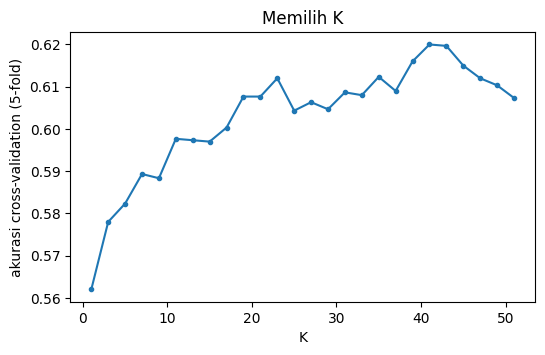

K terbaik: 41 | akurasi: 0.62


In [8]:
Xk = loan3000[['borrower_score', 'payment_inc_ratio']]
yk = loan3000['outcome']

from sklearn.pipeline import make_pipeline
ks = list(range(1, 52, 2))
cv_acc = []
for k in ks:
    pipe = make_pipeline(preprocessing.StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    cv_acc.append(cross_val_score(pipe, Xk, yk, cv=5).mean())

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(ks, cv_acc, marker='o', ms=3)
ax.set_xlabel('K'); ax.set_ylabel('akurasi cross-validation (5-fold)')
ax.set_title('Memilih K')
plt.show()
best_k = ks[int(np.argmax(cv_acc))]
print('K terbaik:', best_k, '| akurasi:', round(max(cv_acc), 4))

**Interpretasi hasil (bagian tambahan):**
- Akurasi cross-validation naik tajam dari K=1 (±0,56) hingga K sekitar 20, lalu bergerak naik-turun dan mencapai puncak di **K = 41** dengan akurasi **0,62**.
- Pola ini sesuai teori: K=1 *overfit* pada data yang *noisy*, sedangkan data pinjaman dengan SNR rendah cocok dengan K yang lebih besar. Setelah puncak, akurasi mulai turun pelan (*oversmoothing*).
- Akurasi maksimum hanya 0,62, sehingga KNN dengan dua variabel ini tergolong lemah, seperti disebut buku bahwa KNN sendirian jarang kompetitif.

### Teori: KNN sebagai "Feature Engine"

Sendirian, KNN biasanya tidak kompetitif dengan teknik klasifikasi yang lebih canggih. Namun dalam praktik, KNN dapat menambahkan "pengetahuan lokal" dalam proses bertahap bersama metode lain:
1. Jalankan KNN pada data. Untuk tiap record, turunkan klasifikasi (atau kuasi-probabilitas kelas).
2. Tambahkan hasil itu sebagai fitur baru, lalu jalankan metode klasifikasi lain. Prediktor asli dengan demikian dipakai dua kali.

Ini tidak menimbulkan masalah multikolinearitas karena informasi yang masuk ke model tahap kedua bersifat sangat lokal (hanya dari beberapa record terdekat), sehingga merupakan informasi tambahan, bukan redundan. Pendekatan ini bisa dipandang sebagai bentuk *ensemble learning* sekaligus *feature engineering*.

Analogi pada data rumah: agen properti menentukan harga berdasarkan penjualan rumah serupa ("comps"), yaitu KNN manual. Fitur baru dari KNN regression (rata-rata harga K tetangga) meniru hal itu. Pada data pinjaman, kita buat fitur yang mewakili kelayakan kredit peminjam, yaitu `borrower_score`.

### Kode
> **Catatan.** Kode buku memakai `predict_proba(X)[:, 1]`. Pada scikit-learn, kolom 1 adalah kelas kedua secara abjad, yaitu `paid off`. Agar fitur ini benar-benar bermakna sebagai probabilitas **default** (sesuai deskripsi buku), kolom `default` diambil secara eksplisit lewat `classes_`. Kolom hasilnya diberi nama baru agar `borrower_score` asli pada data tidak tertimpa.

In [9]:
predictors = ['dti', 'revol_bal', 'revol_util', 'open_acc',
              'delinq_2yrs_zero', 'pub_rec_zero']
outcome = 'outcome'

X = loan_data[predictors]
y = loan_data[outcome]

knn = KNeighborsClassifier(n_neighbors=20)
knn.fit(X, y)

col_default = list(knn.classes_).index('default')
loan_data['borrower_score_knn'] = knn.predict_proba(X)[:, col_default]
loan_data['borrower_score_knn'].describe()

count    45342.000000
mean         0.501098
std          0.128736
min          0.000000
25%          0.400000
50%          0.500000
75%          0.600000
max          0.950000
Name: borrower_score_knn, dtype: float64

**Interpretasi hasil:**
- Fitur `borrower_score_knn` (probabilitas default dari 20 tetangga) memiliki rata-rata 0,501, kuartil 0,4 / 0,5 / 0,6, dan maksimum 0,95. Ringkasan ini sama dengan hasil R pada buku.
- Karena dihitung dari K = 20 tetangga, nilainya berupa kelipatan 0,05.
- Fitur ini bisa ditambahkan ke model tahap kedua sebagai informasi "lokal" tentang riwayat kredit peminjam.

---
## 2. Tree Models

### Teori

Model pohon (juga disebut *Classification and Regression Trees*, CART, *decision trees*, atau sekadar *trees*) adalah metode klasifikasi dan regresi yang efektif dan populer, dikembangkan oleh Leo Breiman dkk. pada 1984. Pohon dan turunannya yang lebih kuat (random forest dan boosted trees) membentuk dasar alat pemodelan prediktif yang paling banyak dipakai dalam data science.

**Istilah kunci**
- **Recursive partitioning:** membagi dan membagi lagi data berulang kali agar outcome di tiap subdivisi akhir sehomogen mungkin.
- **Split value:** nilai prediktor yang membagi record menjadi yang lebih kecil dan yang lebih besar dari nilai tersebut.
- **Node:** representasi grafis atau aturan dari sebuah split.
- **Leaf:** ujung dari serangkaian aturan if-then; aturan yang mengarah ke leaf adalah satu aturan klasifikasi.
- **Loss:** jumlah salah klasifikasi pada suatu tahap; makin banyak loss, makin tidak murni.
- **Impurity (heterogeneity):** seberapa tercampur kelas dalam suatu subpartisi (lawan: *homogeneity*, *purity*).
- **Pruning:** memangkas cabang pohon yang tumbuh penuh untuk mengurangi overfitting.

Model pohon adalah himpunan aturan "if-then-else" yang mudah dipahami dan diimplementasikan. Berbeda dengan regresi linear dan logistik, pohon dapat menemukan pola tersembunyi berupa interaksi kompleks, dan berbeda dengan KNN atau Naive Bayes, pohon sederhana dapat diekspresikan sebagai hubungan prediktor yang mudah ditafsirkan.

> *Decision tree* pada riset operasi memiliki arti berbeda (dan lebih tua): proses analisis keputusan manusia dengan memilih jalur keputusan dengan nilai harapan maksimum.

### Kode: contoh sederhana
Pohon dilatih pada `loan3000` dengan prediktor `borrower_score` dan `payment_inc_ratio`.

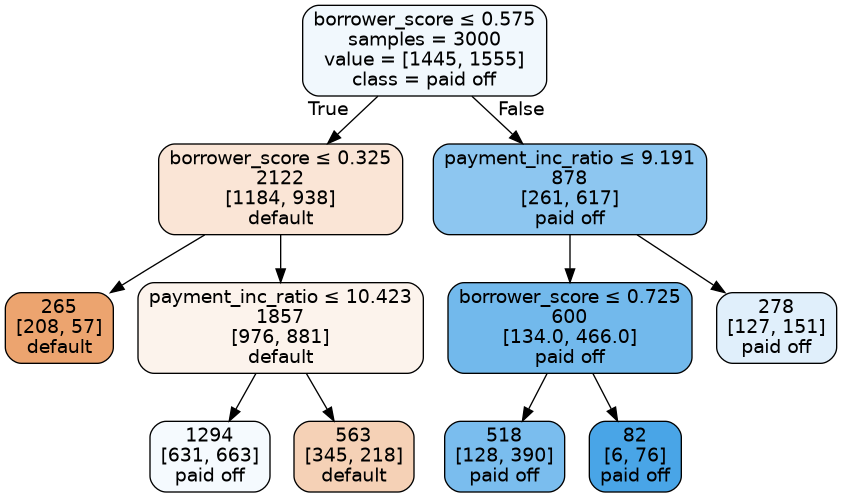

In [10]:
predictors = ['borrower_score', 'payment_inc_ratio']
outcome = 'outcome'

X = loan3000[predictors]
y = loan3000[outcome]

loan_tree = DecisionTreeClassifier(random_state=1, criterion='entropy',
                                   min_impurity_decrease=0.003)
loan_tree.fit(X, y)
plotDecisionTree(loan_tree, feature_names=predictors,
                 class_names=loan_tree.classes_)

In [11]:
print(textDecisionTree(loan_tree))

node=0 test node: go to node 1 if 0 <= 0.5750000178813934 else to node 6
  node=1 test node: go to node 2 if 0 <= 0.32500000298023224 else to node 3
    node=2 leaf node: [[np.float64(0.785), np.float64(0.215)]]
    node=3 test node: go to node 4 if 1 <= 10.42264986038208 else to node 5
      node=4 leaf node: [[np.float64(0.488), np.float64(0.512)]]
      node=5 leaf node: [[np.float64(0.613), np.float64(0.387)]]
  node=6 test node: go to node 7 if 1 <= 9.19082498550415 else to node 10
    node=7 test node: go to node 8 if 0 <= 0.7249999940395355 else to node 9
      node=8 leaf node: [[np.float64(0.247), np.float64(0.753)]]
      node=9 leaf node: [[np.float64(0.073), np.float64(0.927)]]
    node=10 leaf node: [[np.float64(0.457), np.float64(0.543)]]


Aturan klasifikasi diperoleh dengan menelusuri pohon dari akar: ke kiri jika kondisi benar, ke kanan jika tidak, sampai mencapai leaf. Hasil R dan Python tidak identik karena implementasi yang berbeda; itu normal.

Gambar berikut menunjukkan **partisi ruang prediktor** yang dibentuk pohon tersebut (setara Figure 6-4): tiap persegi panjang adalah satu leaf.

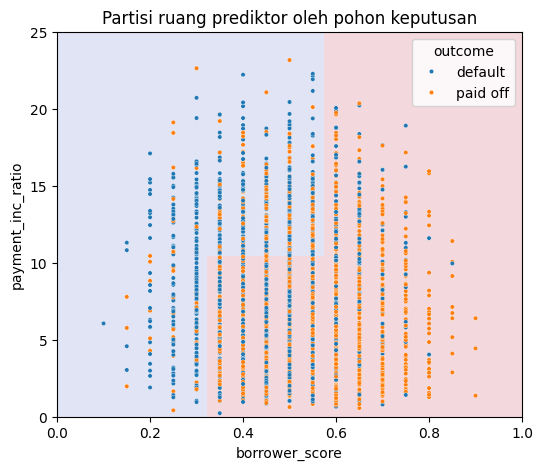

In [12]:
fig, ax = plt.subplots(figsize=(6, 5))
DecisionBoundaryDisplay.from_estimator(loan_tree, X, response_method='predict',
                                       alpha=0.15, ax=ax, grid_resolution=300,
                                       plot_method='pcolormesh', cmap='coolwarm', shading='auto')
sns.scatterplot(data=loan3000, x='borrower_score', y='payment_inc_ratio',
                hue='outcome', s=10, ax=ax)
ax.set_ylim(0, 25); ax.set_xlim(0, 1)
ax.set_title('Partisi ruang prediktor oleh pohon keputusan')
plt.show()

**Interpretasi hasil:**
- Aturan teratas: `borrower_score ≤ 0,575`. Jika tidak (skor tinggi), pinjaman cenderung *paid off*. Jika ya, pohon memeriksa `borrower_score ≤ 0,325` (leaf berisi 265 pinjaman, 208 di antaranya default), lalu `payment_inc_ratio`.
- Teks pohon identik dengan keluaran Python pada buku (hasil R sedikit berbeda karena implementasi berbeda).
- Pada plot partisi, **latar biru = prediksi default** dan **merah muda = prediksi paid off**, sedangkan titik biru = default dan oranye = paid off. Tiap persegi panjang adalah satu leaf.

### Teori: Algoritma recursive partitioning

Untuk respons $Y$ dan $P$ prediktor $X_j$, pada suatu partisi $A$ algoritma mencari cara terbaik membaginya menjadi dua subpartisi:
1. Untuk tiap prediktor $X_j$ dan tiap nilai $s_j$: bagi record di $A$ menjadi $X_j < s_j$ dan $X_j \geq s_j$, lalu ukur homogenitas kelas pada tiap subpartisi.
2. Pilih pasangan variabel dan nilai split yang menghasilkan homogenitas dalam-partisi tertinggi.

Bagian rekursifnya:
1. Inisialisasi $A$ dengan seluruh data.
2. Terapkan algoritma partisi untuk membagi $A$ menjadi $A_1$ dan $A_2$.
3. Ulangi langkah 2 pada $A_1$ dan $A_2$.
4. Berhenti ketika tidak ada lagi partisi yang cukup meningkatkan homogenitas.

Selain prediksi biner, pohon dapat memberi estimasi probabilitas: $\text{Prob}(Y=1)$ = jumlah 1 pada partisi dibagi ukuran partisi.

### Teori: Mengukur homogenitas / impurity

Akurasi bukan ukuran impurity yang baik. Dua ukuran yang umum untuk kasus biner (dengan $p$ = proporsi record kelas 1 dalam partisi):

$$\text{Gini}: \; I(A)=p(1-p) \qquad\qquad \text{Entropy}: \; I(A)=-p\log_2 p-(1-p)\log_2(1-p)$$

Keduanya bernilai terendah (0) saat partisi murni dan tertinggi saat $p = 0{,}5$. Entropy memberi skor impurity yang lebih tinggi pada tingkat akurasi sedang dan tinggi. Untuk tiap kandidat split, impurity dihitung pada tiap partisi hasil split, dirata-ratakan berbobot (menurut ukuran partisi), lalu dipilih split dengan rata-rata terendah.

> **Gini impurity bukan Gini coefficient.** Gini coefficient terbatas pada klasifikasi biner dan berkaitan dengan AUC.

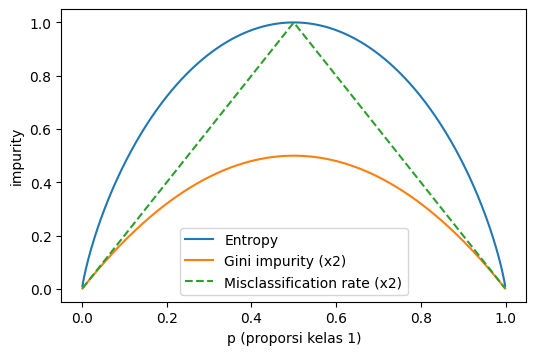

In [13]:
# Figure 6-5: Gini impurity (diskalakan), entropy, dan tingkat salah klasifikasi
p = np.linspace(0.001, 0.999, 500)
gini = 2 * p * (1 - p)                       # dikali 2 agar puncaknya 0.5, seperti pada buku
entropy = -p * np.log2(p) - (1 - p) * np.log2(1 - p)
misclass = np.minimum(p, 1 - p) * 2           # error rate (diskalakan)

fig, ax = plt.subplots(figsize=(6, 3.8))
ax.plot(p, entropy, label='Entropy')
ax.plot(p, gini, label='Gini impurity (x2)')
ax.plot(p, misclass, label='Misclassification rate (x2)', ls='--')
ax.set_xlabel('p (proporsi kelas 1)'); ax.set_ylabel('impurity')
ax.legend()
plt.show()

### Teori: Menghentikan pertumbuhan pohon

Semakin besar pohon, aturan semakin rinci: bergeser dari aturan "besar" yang mencerminkan hubungan nyata ke aturan "kecil" yang hanya mencerminkan *noise*. Pohon yang tumbuh penuh menghasilkan leaf yang murni dan akurasi 100% pada data latih, tetapi akurasi itu semu. Ini adalah **overfitting**.

Cara menghentikan pembelahan:
- **Ukuran partisi atau leaf minimum.** Di Python: `min_samples_split` (default 2) dan `min_samples_leaf` (default 1). Di R (`rpart`): `minsplit` (20) dan `minbucket` (7).
- **Penurunan impurity minimum.** Jangan membelah jika partisi baru tidak mengurangi impurity secara cukup berarti. Di Python: `min_impurity_decrease` (nilai lebih kecil menghasilkan pohon lebih kompleks). Di R: *complexity parameter* `cp`.

Aturan ini bersifat sewenang-wenang. Untuk menentukan nilai optimum perlu dikombinasikan dengan *cross-validation*, baik dengan mengubah parameter secara sistematis maupun dengan *pruning*.

**Mengendalikan kompleksitas di Python.** *Complexity parameter* dan pruning versi R tidak tersedia pada pohon scikit-learn. Solusinya adalah **grid search** atas kombinasi nilai parameter, digabung dengan cross-validation lewat `GridSearchCV`. Parameter optimal dipilih dari performa hasil cross-validation.

In [14]:
param_grid = {
    'max_depth': [5, 10, 15, 20, 30],
    'min_samples_split': [20, 40, 60, 80, 100],
    'min_impurity_decrease': [0, 0.0005, 0.001, 0.0025, 0.005],
}
gridSearch = GridSearchCV(DecisionTreeClassifier(random_state=1), param_grid, cv=5)
gridSearch.fit(X, y)

print('skor cross-validation terbaik:', round(gridSearch.best_score_, 4))
print('parameter terbaik            :', gridSearch.best_params_)

skor cross-validation terbaik: 0.6123
parameter terbaik            : {'max_depth': 5, 'min_impurity_decrease': 0.0005, 'min_samples_split': 20}


**Interpretasi hasil:**
- Grid search dengan 5-fold cross-validation memilih pohon yang relatif kecil: `max_depth=5`, `min_samples_split=20`, `min_impurity_decrease=0,0005`, dengan akurasi CV sekitar **0,612**.
- Akurasi ini sama rendahnya dengan model lain pada data ini, menegaskan bahwa data `loan3000` sangat *noisy*. Mengatur kompleksitas pohon lewat cross-validation mencegah overfitting.

### Teori: Memprediksi nilai kontinu (regression tree)

Prediksi nilai kontinu dengan pohon mengikuti logika dan prosedur yang sama, kecuali impurity diukur dengan **kuadrat deviasi dari rata-rata** (squared error) pada tiap subpartisi, dan performa prediksi dinilai dengan **RMSE**. Prediksi tiap leaf adalah rata-rata nilai respons pada leaf tersebut. Di scikit-learn dipakai `DecisionTreeRegressor`.

Buku tidak menyertakan kode untuk bagian ini. Ilustrasi berikut (**tambahan**, data sintetis) menunjukkan bahwa prediksi pohon regresi berupa fungsi tangga: konstan di tiap leaf.

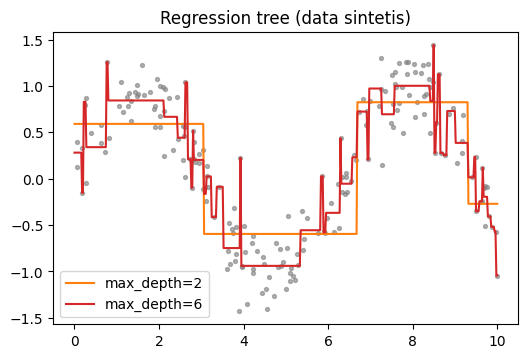

In [15]:
rng = np.random.default_rng(1)
xs = np.sort(rng.uniform(0, 10, 200))
ys = np.sin(xs) + rng.normal(0, 0.3, 200)

fig, ax = plt.subplots(figsize=(6, 3.8))
ax.scatter(xs, ys, s=8, color='gray', alpha=0.6)
grid_x = np.linspace(0, 10, 500).reshape(-1, 1)
for depth, color in [(2, 'C1'), (6, 'C3')]:
    reg = DecisionTreeRegressor(max_depth=depth, random_state=1).fit(xs.reshape(-1, 1), ys)
    ax.plot(grid_x, reg.predict(grid_x), color=color, label=f'max_depth={depth}')
ax.legend(); ax.set_title('Regression tree (data sintetis)')
plt.show()

### Teori: Bagaimana pohon dipakai

Hambatan umum bagi pemodel prediktif di organisasi adalah anggapan bahwa metode mereka adalah "kotak hitam". Pohon punya dua nilai tambah:
- Pohon adalah **alat visual** untuk mengeksplorasi data: variabel mana yang penting dan bagaimana hubungannya (termasuk hubungan nonlinear).
- Pohon menghasilkan **aturan** yang dapat dikomunikasikan kepada non-spesialis, baik untuk implementasi maupun untuk "menjual" proyek data mining.

Namun untuk prediksi murni, hasil gabungan banyak pohon (random forest dan boosted trees) hampir selalu lebih akurat. Sayangnya keunggulan interpretasi pohon tunggal hilang pada model gabungan.

---
## 3. Bagging dan Random Forest

### Teori

Pada 1906, Sir Francis Galton menghadiri sebuah kontes tebak berat sapi di pameran. Dari 800 tebakan yang bervariasi lebar, rata-rata dan median ternyata berada dalam 1% dari berat sebenarnya. Prinsip *wisdom of crowds* ini berlaku untuk model prediktif: **merata-ratakan** (atau voting mayoritas) banyak model, yaitu sebuah **ensemble**, lebih akurat daripada memilih satu model. Pendekatan ensemble dipakai secara publik pada Netflix Prize.

**Istilah kunci**
- **Ensemble:** membentuk prediksi dengan sekumpulan model (sinonim: *model averaging*).
- **Bagging:** teknik umum membentuk kumpulan model dengan *bootstrapping* data (sinonim: *bootstrap aggregation*).
- **Random forest:** bagged estimate berbasis pohon keputusan (sinonim: *bagged decision trees*).
- **Variable importance:** ukuran kepentingan sebuah prediktor bagi performa model.

Versi sederhana ensemble: (1) bangun model prediktif dan catat prediksinya, (2) ulangi untuk banyak model pada data yang sama, (3) untuk tiap record ambil rata-rata (atau rata-rata berbobot, atau voting mayoritas) prediksi. Dua varian utama ensemble: **bagging** (random forest) dan **boosting** (boosted trees).

**Bagging** (*bootstrap aggregating*, Leo Breiman, 1994) seperti ensemble dasar, tetapi tiap model dilatih pada **bootstrap resample** (pengambilan sampel dengan pengembalian), bukan data yang sama:
1. Inisialisasi $M$ (jumlah model) dan $n$ (jumlah record per sampel).
2. Ambil bootstrap resample $n$ record dari data latih (sebuah "bag").
3. Latih model pada bag tersebut.
4. Ulangi sampai $M$ model terbentuk.

Jika model $f_m$ memprediksi probabilitas $Y=1$, estimasi bagging adalah rata-ratanya:

$$\hat{f}=\frac{1}{M}\big(\hat{f}_1(X)+\hat{f}_2(X)+\cdots+\hat{f}_M(X)\big)$$

**Random forest** adalah bagging pada pohon keputusan dengan satu perluasan penting: selain mengambil sampel *record*, algoritma juga mengambil sampel *variabel*. Pada setiap split, pilihan variabel dibatasi pada subset acak $p < P$ variabel (tanpa pengembalian). Aturan praktis: $p \approx \sqrt{P}$. Dengan demikian pohon-pohon menjadi lebih beragam dan rata-ratanya lebih stabil.

**Out-of-bag (OOB) error.** Karena tiap pohon dilatih pada bootstrap sampel, sebagian record tidak ikut dalam sampel itu ("out-of-bag"). Error OOB adalah tingkat kesalahan tiap pohon pada record yang tidak dipakai melatihnya, dan berfungsi sebagai estimasi error yang mirip hasil cross-validation.

### Kode: random forest dengan dua variabel

In [16]:
predictors = ['borrower_score', 'payment_inc_ratio']
outcome = 'outcome'

X = loan3000[predictors]
y = loan3000[outcome]

rf = RandomForestClassifier(n_estimators=500, random_state=1, oob_score=True)
rf.fit(X, y)
print('OOB error rate:', round(1 - rf.oob_score_, 4))

OOB error rate: 0.4247


Implementasi `RandomForestClassifier` tidak punya cara mudah untuk mendapatkan estimasi OOB sebagai fungsi jumlah pohon. Solusi dari buku: latih serangkaian classifier dengan jumlah pohon yang meningkat dan catat `oob_score_` (kurang efisien, tetapi sederhana).

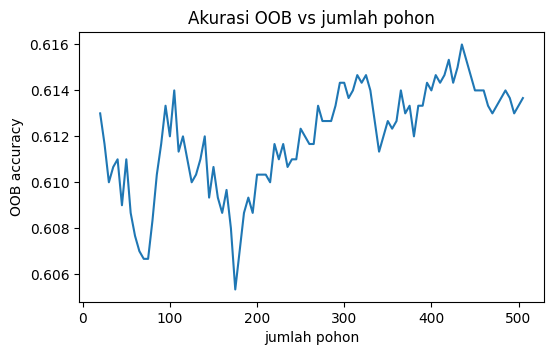

In [17]:
n_estimator = list(range(20, 510, 5))
oobScores = []
for n in n_estimator:
    rf_n = RandomForestClassifier(n_estimators=n, criterion='entropy',
                                  max_depth=5, random_state=1, oob_score=True)
    rf_n.fit(X, y)
    oobScores.append(rf_n.oob_score_)

df = pd.DataFrame({'n': n_estimator, 'oobScore': oobScores})
ax = df.plot(x='n', y='oobScore', figsize=(6, 3.5), legend=False)
ax.set_xlabel('jumlah pohon'); ax.set_ylabel('OOB accuracy')
ax.set_title('Akurasi OOB vs jumlah pohon')
plt.show()

**Interpretasi hasil:**
- Random forest 500 pohon dengan dua prediktor memiliki **OOB error 0,425** (akurasi OOB ≈ 0,575) saat pohon dibiarkan tumbuh penuh. Buku melaporkan 39,2% di R, perbedaan wajar karena implementasi berbeda.
- Pada kurva dengan `max_depth=5`, akurasi OOB berfluktuasi antara 0,605 dan 0,616 dan stabil di sekitar **0,613 sampai 0,614** (error ≈ 0,386, sesuai plateau ±0,385 pada buku).
- Kurva ini **tidak** menunjukkan penurunan error tajam dari 0,44 seperti pada Figure 6-6 di buku. Dengan `max_depth=5`, hutan kecil pun sudah cukup baik. Intinya sama: menambah pohon tidak membuat overfit, dan setelah jumlah tertentu hasilnya stabil.

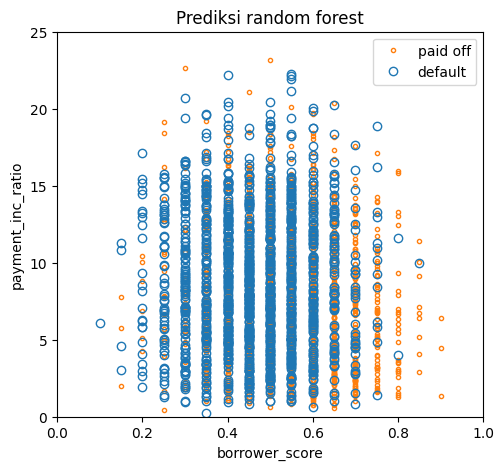

In [18]:
predictions = X.copy()
predictions['prediction'] = rf.predict(X)

fig, ax = plt.subplots(figsize=(5.5, 5))
predictions.loc[predictions.prediction == 'paid off'].plot(
    x='borrower_score', y='payment_inc_ratio', style='.',
    markerfacecolor='none', markeredgecolor='C1', ax=ax)
predictions.loc[predictions.prediction == 'default'].plot(
    x='borrower_score', y='payment_inc_ratio', style='o',
    markerfacecolor='none', markeredgecolor='C0', ax=ax)
ax.legend(['paid off', 'default'])
ax.set_xlim(0, 1)
ax.set_ylim(0, 25)
ax.set_xlabel('borrower_score')
ax.set_ylabel('payment_inc_ratio')
ax.set_title('Prediksi random forest')
plt.show()

**Interpretasi hasil:**
- Prediksi random forest lebih "berbintik" daripada aturan pohon tunggal yang rapi. Sebagian peminjam dengan skor sangat tinggi tetap diprediksi default akibat record yang tidak biasa, contoh bahaya overfitting.
- Random forest lebih akurat daripada pohon tunggal, tetapi aturan keputusannya yang mudah dibaca hilang (sifat "kotak hitam").

### Teori: Variable importance

Kekuatan random forest terlihat pada data dengan banyak fitur dan record: ia otomatis menentukan prediktor mana yang penting dan menemukan hubungan kompleks (termasuk interaksi). Ada dua cara mengukur *variable importance*:

1. **Penurunan akurasi (mean decrease in accuracy, `type=1`).** Nilai suatu variabel diacak (*permuted*) secara acak, yang menghilangkan semua daya prediksinya, lalu diukur seberapa turun akurasi model. Di R dihitung dari data OOB, sehingga efektif merupakan estimasi cross-validated.
2. **Penurunan Gini impurity (mean decrease in node impurity, `type=2`).** Rata-rata penurunan skor Gini impurity pada semua node yang dibelah dengan variabel tersebut. Diukur pada data latih, sehingga kurang andal.

Jika penurunan akurasi lebih andal, mengapa tetap memakai penurunan Gini? Karena Gini adalah *produk sampingan* algoritma (hampir gratis), sedangkan akurasi per variabel butuh komputasi tambahan. Di lingkungan produksi dengan ribuan model, selisih komputasi itu bisa penting. Selain itu penurunan Gini menunjukkan variabel mana yang dipakai random forest untuk aturan splitting.

### Kode: model lengkap dengan semua variabel

In [19]:
predictors = ['loan_amnt', 'term', 'annual_inc', 'dti', 'payment_inc_ratio',
              'revol_bal', 'revol_util', 'purpose', 'delinq_2yrs_zero',
              'pub_rec_zero', 'open_acc', 'grade', 'emp_length', 'purpose_',
              'home_', 'emp_len_', 'borrower_score']
outcome = 'outcome'

X = pd.get_dummies(loan_data[predictors], drop_first=True)
y = loan_data[outcome]

rf_all = RandomForestClassifier(n_estimators=500, random_state=1)
rf_all.fit(X, y)
print('jumlah fitur setelah one-hot:', X.shape[1])

jumlah fitur setelah one-hot: 33


In [20]:
rf = RandomForestClassifier(n_estimators=500, random_state=1)
scores = defaultdict(list)

# cross-validate skor pada beberapa pembagian acak data
for _ in range(3):
    train_X, valid_X, train_y, valid_y = train_test_split(X, y, test_size=0.3)
    rf.fit(train_X, train_y)
    acc = metrics.accuracy_score(valid_y, rf.predict(valid_X))
    for column in X.columns:
        X_t = valid_X.copy()
        X_t[column] = np.random.permutation(X_t[column].values)

        shuff_acc = metrics.accuracy_score(valid_y, rf.predict(X_t))
        scores[column].append((acc - shuff_acc) / acc)

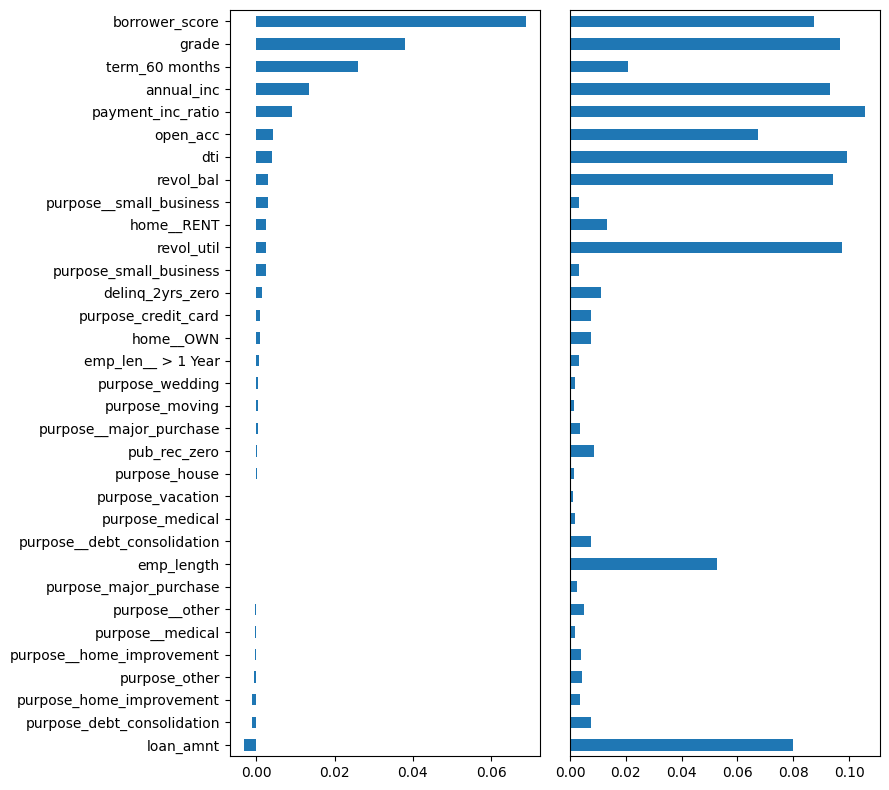

In [21]:
df = pd.DataFrame({
    'feature': X.columns,
    'Accuracy decrease': [np.mean(scores[column]) for column in X.columns],
    'Gini decrease': rf_all.feature_importances_,
})
df = df.sort_values('Accuracy decrease')

fig, axes = plt.subplots(ncols=2, figsize=(9, 8))
ax = df.plot(kind='barh', x='feature', y='Accuracy decrease',
             legend=False, ax=axes[0])
ax.set_ylabel('')

ax = df.plot(kind='barh', x='feature', y='Gini decrease',
             legend=False, ax=axes[1])
ax.set_ylabel('')
ax.get_yaxis().set_visible(False)
plt.tight_layout()
plt.show()

**Interpretasi hasil:**
- Model penuh memakai 33 fitur setelah one-hot encoding.
- Menurut **penurunan akurasi** (panel kiri), variabel terpenting adalah `borrower_score`, lalu `grade` dan `term_60 months`. `loan_amnt` dan beberapa dummy `purpose` memiliki nilai sekitar nol atau sedikit negatif (mengacak variabel itu tidak merugikan, artinya hampir tidak berguna).
- Menurut **penurunan Gini** (panel kanan), peringkatnya berbeda: variabel numerik kontinu seperti `payment_inc_ratio`, `dti`, `revol_util`, `annual_inc`, dan `revol_bal` tampak tinggi. Penurunan Gini cenderung menguntungkan variabel dengan banyak nilai unik dan dihitung pada data latih, sehingga kurang andal, sama seperti peringatan buku.

### Teori: Hyperparameters

Random forest adalah algoritma "kotak hitam" dengan "kenop" untuk mengatur cara kerjanya. Kenop ini disebut **hyperparameter**: parameter yang harus ditetapkan *sebelum* model dilatih dan tidak dioptimalkan selama pelatihan. Untuk random forest, dua yang terpenting (terutama untuk mencegah overfitting):
- **`nodesize` / `min_samples_leaf`:** ukuran minimum node terminal (leaf).
- **`maxnodes` / `max_leaf_nodes`:** jumlah node maksimum tiap pohon. Pada Python yang ditentukan adalah jumlah leaf maksimum; keduanya berkaitan: $\text{maxnodes}=2\times\text{max\_leaf\_nodes}-1$ (pohon biner dengan $L$ leaf memiliki $2L-1$ node).

Memakai nilai default bisa menyebabkan overfitting pada data *noisy*. Menaikkan `min_samples_leaf` atau membatasi `max_leaf_nodes` membuat pohon lebih kecil dan mengurangi aturan palsu. Efek hyperparameter diuji dengan cross-validation.

### Tambahan: pengaruh `min_samples_leaf` terhadap akurasi OOB
Bagian ini tambahan (tidak ada di buku) untuk memperlihatkan efek hyperparameter pada data `loan3000` yang *noisy*.

In [22]:
Xh = loan3000[['borrower_score', 'payment_inc_ratio']]
yh = loan3000['outcome']

rows = []
for leaf in [1, 5, 10, 25, 50, 100]:
    m = RandomForestClassifier(n_estimators=300, min_samples_leaf=leaf,
                               random_state=1, oob_score=True).fit(Xh, yh)
    rows.append({'min_samples_leaf': leaf, 'OOB accuracy': m.oob_score_,
                 'train accuracy': m.score(Xh, yh)})
pd.DataFrame(rows).round(4)

,min_samples_leaf,OOB accuracy,train accuracy
0,1,0.5737,0.9987
1,5,0.5913,0.7683
2,10,0.5950,0.7100
3,25,0.6013,0.6610
4,50,0.6067,0.6403
5,100,0.6117,0.6340


**Interpretasi hasil (bagian tambahan):**
- Dengan `min_samples_leaf=1` (default), akurasi latih mencapai 0,999 tetapi akurasi OOB hanya 0,574: model menghafal data latih (overfit).
- Menaikkan `min_samples_leaf` menurunkan akurasi latih (menjadi 0,634 pada nilai 100) namun **menaikkan akurasi OOB** (menjadi 0,612). Jarak antara keduanya mengecil.
- Hasil ini mendukung saran buku: pada data *noisy*, hyperparameter default dapat menyebabkan overfitting dan sebaiknya di-tuning dengan cross-validation.

---
## 4. Boosting

### Teori

Boosting adalah teknik umum untuk membangun ensemble yang dikembangkan hampir bersamaan dengan bagging. Seperti bagging, boosting paling sering dipakai dengan pohon keputusan, tetapi pendekatannya sangat berbeda: boosting memiliki lebih banyak "bel dan peluit" dan butuh kehati-hatian lebih. (Analogi buku: bagging seperti Honda Accord, andal dan stabil; boosting seperti Porsche, bertenaga tetapi butuh perawatan.)

Pada regresi linear, residual sering diperiksa untuk memperbaiki fit. Boosting membawa konsep ini lebih jauh: ia melatih **serangkaian model**, di mana setiap model berikutnya berusaha meminimalkan error model sebelumnya. Varian yang umum: **AdaBoost**, **gradient boosting**, dan **stochastic gradient boosting** (paling umum dan paling umum dipakai; dengan parameter yang tepat dapat meniru random forest).

**Istilah kunci**
- **Boosting:** menyusun barisan model dengan memberi bobot lebih pada record dengan residual besar di tiap putaran.
- **AdaBoost:** versi awal boosting yang membobot ulang data berdasarkan residual.
- **Gradient boosting:** bentuk lebih umum, dirumuskan sebagai minimisasi fungsi biaya.
- **Stochastic gradient boosting:** versi paling umum, dengan resampling record dan kolom di tiap putaran.
- **Regularization:** teknik mencegah overfitting dengan menambah penalti pada fungsi biaya terhadap jumlah parameter model.
- **Hyperparameters:** parameter yang harus ditetapkan sebelum algoritma dijalankan.

**Algoritma AdaBoost**
1. Inisialisasi $M$ (jumlah maksimum model), iterasi $m=1$, bobot observasi $w_i=1/N$, dan ensemble $F_0=0$.
2. Dengan bobot observasi, latih model $f_m$ yang meminimalkan error berbobot $e_m$ (jumlah bobot observasi yang salah diklasifikasikan).
3. Tambahkan model ke ensemble: $F_m=F_{m-1}+\alpha_m f_m$, dengan $\alpha_m=\log\dfrac{1-e_m}{e_m}$.
4. Perbarui bobot sehingga bobot observasi yang salah diklasifikasikan **naik** (makin besar jika $\alpha_m$ makin besar).
5. Naikkan $m$. Jika $m \le M$, kembali ke langkah 2.

Estimasi boosted: $F=\alpha_1 f_1+\alpha_2 f_2+\cdots+\alpha_M f_M$. Dengan menaikkan bobot observasi yang salah, algoritma memaksa model berikutnya berlatih lebih keras pada data yang sulit. Faktor $\alpha_m$ memastikan model dengan error lebih rendah punya bobot lebih besar.

**Gradient boosting** serupa AdaBoost, tetapi merumuskan masalah sebagai optimisasi fungsi biaya. Alih-alih mengubah bobot, ia mencocokkan model pada *pseudo-residual*, yang berefek melatih lebih keras pada residual besar. **Stochastic gradient boosting**, seperti random forest, menambahkan keacakan dengan mengambil sampel observasi dan prediktor di setiap tahap.

**XGBoost** adalah perangkat lunak domain publik yang paling banyak dipakai untuk boosting, implementasi stochastic gradient boosting yang efisien (Tianqi Chen dan Carlos Guestrin). Dua parameter penting: `subsample` (fraksi observasi yang di-sampling di tiap iterasi, tanpa pengembalian) dan `eta` / `learning_rate` (faktor penyusutan/*shrinkage* pada $\alpha_m$; nilai kecil mengurangi perubahan bobot sehingga kurang rentan overfit).

### Kode: XGBoost dengan dua prediktor
XGBoost versi terbaru mewajibkan label numerik, jadi `default` dikodekan 1 dan `paid off` 0. Nilai `learning_rate=0.1` dan `max_depth=3` ditulis eksplisit agar sama dengan setelan yang dipakai buku.

In [23]:
predictors = ['borrower_score', 'payment_inc_ratio']

X = loan3000[predictors]
y = (loan3000['outcome'] == 'default').astype(int)     # 1 = default, 0 = paid off

xgb = XGBClassifier(objective='binary:logistic', subsample=0.63,
                    learning_rate=0.1, max_depth=3, n_estimators=100)
xgb.fit(X, y)

xgb_df = X.copy()
xgb_df['prediction'] = np.where(xgb.predict(X) == 1, 'default', 'paid off')
xgb_df['prob_default'] = xgb.predict_proba(X)[:, 1]
print('train error:', round(np.mean(xgb.predict(X) != y), 4))
xgb_df.head()

train error: 0.3383


,borrower_score,payment_inc_ratio,prediction,prob_default
0,0.40,5.11135,paid off,0.411225
1,0.40,5.43165,default,0.546611
2,0.70,9.23003,paid off,0.335497
3,0.40,2.33482,paid off,0.456195
4,0.45,12.10320,default,0.616080


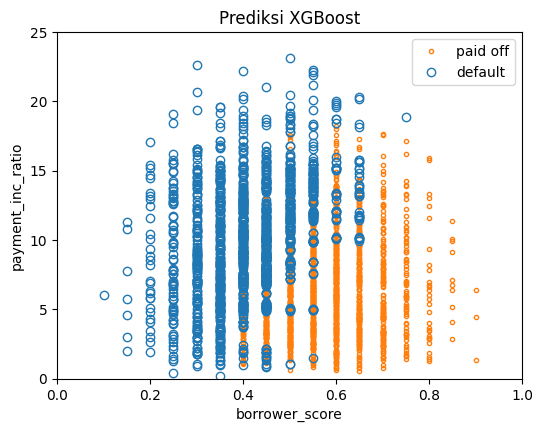

In [24]:
fig, ax = plt.subplots(figsize=(6, 4.5))

xgb_df.loc[xgb_df.prediction == 'paid off'].plot(
    x='borrower_score', y='payment_inc_ratio', style='.',
    markerfacecolor='none', markeredgecolor='C1', ax=ax)
xgb_df.loc[xgb_df.prediction == 'default'].plot(
    x='borrower_score', y='payment_inc_ratio', style='o',
    markerfacecolor='none', markeredgecolor='C0', ax=ax)
ax.legend(['paid off', 'default'])
ax.set_xlim(0, 1)
ax.set_ylim(0, 25)
ax.set_xlabel('borrower_score')
ax.set_ylabel('payment_inc_ratio')
ax.set_title('Prediksi XGBoost')
plt.show()

**Interpretasi hasil:**
- Error latih XGBoost dengan dua prediktor sekitar 0,338. Secara kualitatif prediksinya mirip random forest: berbintik dan sebagian peminjam dengan skor tinggi tetap diprediksi default, seperti dijelaskan buku pada Figure 6-9.

### Teori: Regularization, menghindari overfitting

Penerapan xgboost secara membabi buta dapat menghasilkan model tidak stabil akibat overfitting. Masalahnya dua: (1) akurasi pada data baru menurun, dan (2) prediksi sangat bervariasi sehingga hasilnya tidak stabil. Berbeda dengan random forest yang umumnya sudah baik tanpa tuning, xgboost butuh pengaturan parameter.

Cara mengatasinya: parameter `eta`/`learning_rate` dan `subsample`, serta **regularisasi**, yaitu memodifikasi fungsi biaya dengan menambahkan penalti atas kompleksitas model. Pohon dilatih dengan meminimalkan kriteria biaya seperti Gini impurity; pada xgboost kita dapat menambah suku yang mengukur kompleksitas model. Dua parameter regularisasi:
- `alpha` (`reg_alpha`): regularisasi **L1** (jarak Manhattan).
- `lambda` (`reg_lambda`): regularisasi **L2** (kuadrat jarak Euclidean).

Menaikkan keduanya menghukum model yang lebih kompleks dan mengecilkan ukuran pohon.

> **Ridge regression dan Lasso.** Menambah penalti kompleksitas untuk menghindari overfitting sudah dikenal sejak 1970-an. Regresi kuadrat terkecil meminimalkan RSS. *Ridge* meminimalkan RSS ditambah penalti $\lambda\,(b_1^2+\cdots+b_p^2)$ (L2). *Lasso* memakai penalti $\alpha\,(|b_1|+\cdots+|b_p|)$ (L1, jarak Manhattan). Makin besar $\lambda$ (atau $\alpha$), makin kecil kemungkinan overfit. Parameter `lambda` dan `alpha` pada xgboost bekerja serupa.

### Kode: model default vs model dengan penalti
Data dibagi menjadi 10.000 record uji dan sisanya data latih.

In [25]:
predictors = ['loan_amnt', 'term', 'annual_inc', 'dti', 'payment_inc_ratio',
              'revol_bal', 'revol_util', 'purpose', 'delinq_2yrs_zero',
              'pub_rec_zero', 'open_acc', 'grade', 'emp_length', 'purpose_',
              'home_', 'emp_len_', 'borrower_score']
outcome = 'outcome'

X = pd.get_dummies(loan_data[predictors], drop_first=True)
y = pd.Series([1 if o == 'default' else 0 for o in loan_data[outcome]])

train_X, valid_X, train_y, valid_y = train_test_split(X, y, test_size=10000,
                                                      random_state=1)

xgb_default = XGBClassifier(objective='binary:logistic', n_estimators=250,
                            max_depth=6, reg_lambda=0, learning_rate=0.3,
                            subsample=1)
xgb_default.fit(train_X, train_y)

pred_default = xgb_default.predict_proba(valid_X)[:, 1]
error_default = abs(valid_y - pred_default) > 0.5
print('default: ', np.mean(error_default))
print('default (train error):', np.mean(abs(train_y - xgb_default.predict_proba(train_X)[:, 1]) > 0.5))

default:  0.359
default (train error): 0.10902042895138928


In [26]:
xgb_penalty = XGBClassifier(objective='binary:logistic', n_estimators=250,
                            max_depth=6, reg_lambda=1000, learning_rate=0.1,
                            subsample=0.63)
xgb_penalty.fit(train_X, train_y)
pred_penalty = xgb_penalty.predict_proba(valid_X)[:, 1]
error_penalty = abs(valid_y - pred_penalty) > 0.5
print('penalty: ', np.mean(error_penalty))
print('penalty (train error):', np.mean(abs(train_y - xgb_penalty.predict_proba(train_X)[:, 1]) > 0.5))

penalty:  0.3313
penalty (train error): 0.3117254258389452


Untuk membandingkan error *in-sample* dan *out-of-sample* seiring bertambahnya model (pohon), buku memakai argumen `ntree_limit` agar hanya `i` pohon pertama yang dipakai. Pada XGBoost versi baru argumen ini diganti `iteration_range=(0, i)`. Agar lebih cepat, error dihitung setiap 5 iterasi (buku: setiap iterasi).

In [27]:
results = []
for i in list(range(1, 251, 5)) + [250]:
    rng_i = (0, i)
    train_default = xgb_default.predict_proba(train_X, iteration_range=rng_i)[:, 1]
    train_penalty = xgb_penalty.predict_proba(train_X, iteration_range=rng_i)[:, 1]
    pred_default = xgb_default.predict_proba(valid_X, iteration_range=rng_i)[:, 1]
    pred_penalty = xgb_penalty.predict_proba(valid_X, iteration_range=rng_i)[:, 1]
    results.append({
        'iterations': i,
        'default train': np.mean(abs(train_y - train_default) > 0.5),
        'penalty train': np.mean(abs(train_y - train_penalty) > 0.5),
        'default test': np.mean(abs(valid_y - pred_default) > 0.5),
        'penalty test': np.mean(abs(valid_y - pred_penalty) > 0.5),
    })

results = pd.DataFrame(results)
results.head()

,iterations,default train,penalty train,default test,penalty test
0,1,0.342058,0.354338,0.3486,0.3550
1,6,0.319422,0.335437,0.3344,0.3383
2,11,0.310679,0.335663,0.3334,0.3364
3,16,0.301030,0.334050,0.3341,0.3346
4,21,0.295343,0.332239,0.3334,0.3311


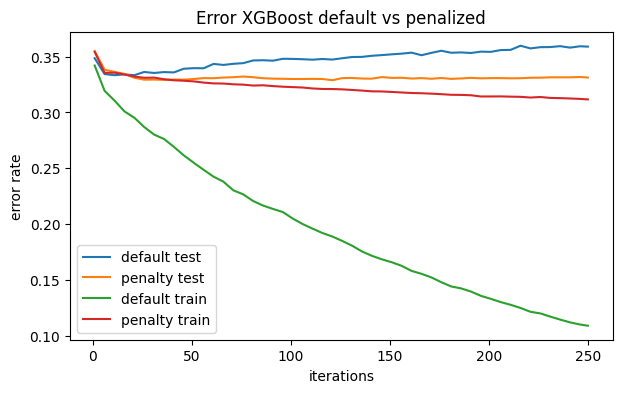

In [28]:
ax = results.plot(x='iterations', y='default test', figsize=(7, 4))
results.plot(x='iterations', y='penalty test', ax=ax)
results.plot(x='iterations', y='default train', ax=ax)
results.plot(x='iterations', y='penalty train', ax=ax)
ax.set_ylabel('error rate')
ax.set_title('Error XGBoost default vs penalized')
plt.show()

**Interpretasi hasil:**
- **Model default** (tanpa regularisasi, `reg_lambda=0`, `learning_rate=0,3`) memiliki error latih **10,9%** tetapi error uji **35,9%**. Jarak sebesar ini adalah tanda overfitting jelas (buku: 13,3% vs 35,3%).
- **Model dengan penalti** (`reg_lambda=1000`, `learning_rate=0,1`, `subsample=0,63`) memiliki error latih 31,2% dan error uji **33,1%**, jauh lebih stabil dan lebih baik pada data baru (buku: 31,0% vs 32,9%).
- Pada grafik, error uji model default justru **naik** seiring bertambahnya iterasi (hingga ±0,36), sedangkan error latihnya terus turun. Model penalti tidak menunjukkan perilaku itu. Ini menunjukkan perlunya regularisasi pada XGBoost, dan pola ini sama dengan Figure 6-10 pada buku.

### Teori: Hyperparameters dan cross-validation

xgboost memiliki banyak hyperparameter, dan pilihan spesifik dapat mengubah hasil secara dramatis. Solusi standar: **cross-validation**. Data dibagi acak menjadi $K$ kelompok (*fold*). Untuk tiap fold, model dilatih pada data di luar fold, lalu dievaluasi pada data di dalam fold. Ini menghasilkan ukuran akurasi pada data *out-of-sample*. Himpunan hyperparameter terbaik adalah yang menghasilkan model dengan error terendah, dirata-ratakan antar-fold.

Contoh di bawah mengeksplorasi dua parameter: shrinkage `eta`/`learning_rate` dan kedalaman maksimum pohon `max_depth` (pohon dalam cenderung kompleks dan bisa overfit). Seluruh kombinasi dibuat dengan `itertools.product`.

**Hyperparameter XGBoost yang utama**

| Parameter | Fungsi |
|---|---|
| `eta` / `learning_rate` | Faktor penyusutan (0 sampai 1) pada $\alpha$. Data *noisy* butuh nilai kecil (misal 0,1). |
| `nrounds` / `n_estimators` | Jumlah putaran boosting. Bila `eta` kecil, putaran perlu diperbanyak. Selama ada pencegahan overfitting, putaran lebih banyak tidak merugikan. |
| `max_depth` | Kedalaman maksimum pohon. Boosting biasanya memakai pohon dangkal (berbeda dengan random forest), sehingga menghindari interaksi kompleks palsu. |
| `subsample`, `colsample_bytree` | Fraksi record dan fraksi prediktor yang di-sampling tanpa pengembalian. Membantu mencegah overfitting. |
| `lambda` / `reg_lambda`, `alpha` / `reg_alpha` | Parameter regularisasi (L2 dan L1). |

### Kode: cross-validation 5-fold untuk `eta` dan `max_depth`
Versi R pada buku memakai 100 putaran (`nrounds=100`), sehingga di sini dipakai `n_estimators=100` agar hasil sebanding dan waktu komputasi lebih singkat (45 model dilatih).

In [29]:
rng_cv = np.random.default_rng(1)
idx = rng_cv.choice(range(5), size=len(X), replace=True)

error = []
for eta, max_depth in product([0.1, 0.5, 0.9], [3, 6, 9]):
    xgb_cv = XGBClassifier(objective='binary:logistic', n_estimators=100,
                           max_depth=max_depth, learning_rate=eta)
    cv_error = []
    for k in range(5):
        fold_idx = idx == k
        train_X_cv = X.loc[~fold_idx]; train_y_cv = y[~fold_idx]
        valid_X_cv = X.loc[fold_idx]; valid_y_cv = y[fold_idx]

        xgb_cv.fit(train_X_cv, train_y_cv)
        pred = xgb_cv.predict_proba(valid_X_cv)[:, 1]
        cv_error.append(np.mean(abs(valid_y_cv - pred) > 0.5))
    error.append({
        'eta': eta,
        'max_depth': max_depth,
        'avg_error': np.mean(cv_error)
    })
    print(error[-1])

errors = pd.DataFrame(error)
errors

{'eta': 0.1, 'max_depth': 3, 'avg_error': np.float64(0.32933927063986673)}


{'eta': 0.1, 'max_depth': 6, 'avg_error': np.float64(0.3314386537299144)}


{'eta': 0.1, 'max_depth': 9, 'avg_error': np.float64(0.33979507083244676)}


{'eta': 0.5, 'max_depth': 3, 'avg_error': np.float64(0.3330502528509064)}


{'eta': 0.5, 'max_depth': 6, 'avg_error': np.float64(0.35771985016125596)}


{'eta': 0.5, 'max_depth': 9, 'avg_error': np.float64(0.3718346450521242)}


{'eta': 0.9, 'max_depth': 3, 'avg_error': np.float64(0.3422087125494384)}


{'eta': 0.9, 'max_depth': 6, 'avg_error': np.float64(0.3791479823328386)}


{'eta': 0.9, 'max_depth': 9, 'avg_error': np.float64(0.3838748395018202)}


,eta,max_depth,avg_error
0,0.1,3,0.329339
1,0.1,6,0.331439
2,0.1,9,0.339795
3,0.5,3,0.333050
4,0.5,6,0.357720
5,0.5,9,0.371835
6,0.9,3,0.342209
7,0.9,6,0.379148
8,0.9,9,0.383875


**Interpretasi hasil:**
- Error cross-validation terendah dicapai oleh `eta=0,1` dengan `max_depth=3` (**32,9%**), disusul `eta=0,1` dengan `max_depth=6` (33,1%). Hasil ini hampir sama dengan tabel buku (32,90%).
- Error cenderung naik jika `eta` besar atau pohon lebih dalam (hingga 38,4% pada `eta=0,9`, `max_depth=9`): pohon dalam dan langkah belajar besar membuat model overfit.
- Kesimpulan seperti pada buku: pohon dangkal dengan learning rate kecil lebih akurat dan lebih stabil, sehingga `eta=0,1` dan `max_depth=3` (atau mungkin 6) adalah pilihan yang baik.

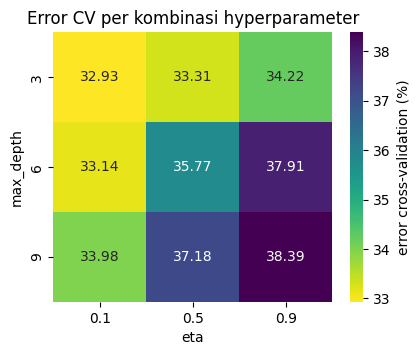

In [30]:
# Ringkasan sebagai heatmap: baris = max_depth, kolom = eta
pivot = errors.pivot(index='max_depth', columns='eta', values='avg_error') * 100
fig, ax = plt.subplots(figsize=(4.5, 3.5))
sns.heatmap(pivot, annot=True, fmt='.2f', cmap='viridis_r', ax=ax,
            cbar_kws={'label': 'error cross-validation (%)'})
ax.set_title('Error CV per kombinasi hyperparameter')
plt.show()

---
## Key Ideas (Rangkuman Chapter 6)

**K-Nearest Neighbors**
- Mengklasifikasikan record ke kelas yang dimiliki record-record serupa.
- Kemiripan ditentukan jarak Euclidean atau metrik terkait.
- K ditentukan dari performa algoritma dengan berbagai nilai K pada data validasi.
- Prediktor biasanya distandardisasi agar variabel berskala besar tidak mendominasi jarak.
- KNN sering dipakai sebagai tahap pertama; nilai prediksinya ditambahkan sebagai prediktor untuk model tahap kedua (non-KNN).

**Tree Models**
- Menghasilkan aturan untuk mengklasifikasikan atau memprediksi outcome lewat pembagian data berturut-turut.
- Tiap split merujuk satu nilai prediktor dan memisahkan data menjadi yang di atas atau di bawah nilai itu, dengan memilih split yang meminimalkan impurity.
- Pohon yang tumbuh penuh overfit dan harus dipangkas atau dibatasi agar menangkap sinyal, bukan *noise*.
- Algoritma banyak-pohon (random forest, boosted trees) lebih akurat tetapi kehilangan daya komunikasi aturan pohon tunggal.

**Bagging dan Random Forest**
- Ensemble meningkatkan akurasi dengan menggabungkan hasil banyak model.
- Bagging: melatih banyak model pada sampel bootstrap lalu merata-ratakannya.
- Random forest: bagging pada pohon, ditambah pengambilan sampel prediktor di setiap split.
- Keluaran berguna: variable importance, yang meranking prediktor menurut kontribusinya pada akurasi.
- Hyperparameter random forest harus di-tuning dengan cross-validation untuk menghindari overfitting.

**Boosting**
- Ensemble berupa barisan model dengan bobot lebih besar pada record yang error-nya besar pada putaran berikutnya.
- Stochastic gradient boosting adalah tipe paling umum dan berperforma terbaik; bentuk paling umum memakai pohon.
- XGBoost adalah paket yang populer dan efisien untuk stochastic gradient boosting.
- Boosting rawan overfitting, sehingga hyperparameter harus di-tuning; regularisasi membantu dengan menghukum kompleksitas.
- Cross-validation sangat penting untuk boosting karena banyaknya hyperparameter.

## Referensi
- Bruce, P., Bruce, A., & Gedeck, P. (2020). *Practical Statistics for Data Scientists*, 2nd ed. O'Reilly. Chapter 6.
- Breiman, L. (2001). "Random Forests." *Machine Learning* 45: 5–32.
- Chen, T. & Guestrin, C. (2016). "XGBoost: A Scalable Tree Boosting System." *KDD '16*.
- Kode dan dataset sumber: https://github.com/gedeck/practical-statistics-for-data-scientists